# Spatial aggregation methods

ERA5 and IMD give data on regular grids. When we aggregate a grid to districts, a small district can contain no grid point. Then that district has no value.

This notebook compares two methods of `aggregate_to_polygons`:

- Point-in-polygon (`point_in_polygon`): the mean of all grid points inside each district.
- Nearest centroid (`nearest_centroid`): the value of the grid point nearest to the center of each district.

In [1]:
import pandas as pd

import varunayan as v

✓ CDS API configuration is already set up and valid.


## District boundaries and climate data

`load_india_boundaries("district")` gives the LGD district boundaries from [geo.bharatviz.org](https://geo.bharatviz.org).

In [2]:
districts = v.load_india_boundaries("district")
districts.head()

,state_name,state_code,district_name,district_code,geometry
0,KARNATAKA,29,Udupi,549,"POLYGON ((74.68871 13.95574, 74.68871 13.95491..."
1,KARNATAKA,29,Shivamogga,547,"POLYGON ((75.08282 14.65279, 75.08418 14.65276..."
2,KARNATAKA,29,Dakshina Kannada,534,"POLYGON ((75.35337 13.184, 75.35393 13.18382, ..."
3,KERALA,32,Kasaragod,558,"POLYGON ((74.99682 12.78912, 74.99724 12.78911..."
4,LAKSHADWEEP,31,Lakshadweep District,553,"MULTIPOLYGON (((73.0132 8.30322, 73.01312 8.30..."


We use two datasets for January 2023. The IMD 1° grid gives the mean daily maximum temperature (column `temperature`, °C). The ERA5 0.25° grid gives the mean 2 m temperature (column `value`, variable `t2m`, °C).

In [3]:
imd = v.imd_temperature_bbox(
    "imd_india_tmax_2023",
    2023,
    2023,
    north=37.5,
    south=7.5,
    east=97.5,
    west=67.5,
    var_type="tmax",
    frequency="monthly",
).query("period == 1")
imd.head()

,year,period,latitude,longitude,temperature
0,2023,1,8.5,73.5,32.460884
1,2023,1,8.5,76.5,30.830639
2,2023,1,8.5,77.5,31.910866
3,2023,1,8.5,78.5,31.210220
4,2023,1,9.5,76.5,30.999754


In [4]:
era5 = v.era5ify_geojson(
    request_id="era5_india_t2m_jan2023",
    variables=["2m_temperature"],
    start_date="2023-01-01",
    end_date="2023-01-31",
    json_file="https://geo.bharatviz.org/geojsons/admin/India-geodata-lgd-states.geojson",
    frequency="monthly",
    resolution=0.25,
)
era5.head()

STARTING ERA5 SINGLE LEVEL PROCESSING


Request ID: era5_india_t2m_jan2023


Variables: ['2m_temperature']


Date Range: 2023-01-01 to 2023-01-31


Frequency: monthly


...

Total complete processing time: 566.18 seconds



First 5 rows of aggregated data:


    datetime  latitude  longitude variable      value  year  month
0 2023-01-01     7.003  93.927888      t2m  26.633698  2023      1
1 2023-01-01     8.253  77.177310      t2m  26.703033  2023      1
2 2023-01-01     8.253  77.427319      t2m  27.029205  2023      1
3 2023-01-01     8.253  77.677328      t2m  26.536041  2023      1
4 2023-01-01     8.503  76.927302      t2m  25.828033  2023      1


ERA5 SINGLE LEVEL PROCESSING COMPLETED SUCCESSFULLY


,datetime,latitude,longitude,variable,value,year,month
0,2023-01-01,7.003,93.927888,t2m,26.633698,2023,1
1,2023-01-01,8.253,77.177310,t2m,26.703033,2023,1
2,2023-01-01,8.253,77.427319,t2m,27.029205,2023,1
3,2023-01-01,8.253,77.677328,t2m,26.536041,2023,1
4,2023-01-01,8.503,76.927302,t2m,25.828033,2023,1


## Grid coverage

`compare_grids` draws the grid points of each dataset on the district boundaries.

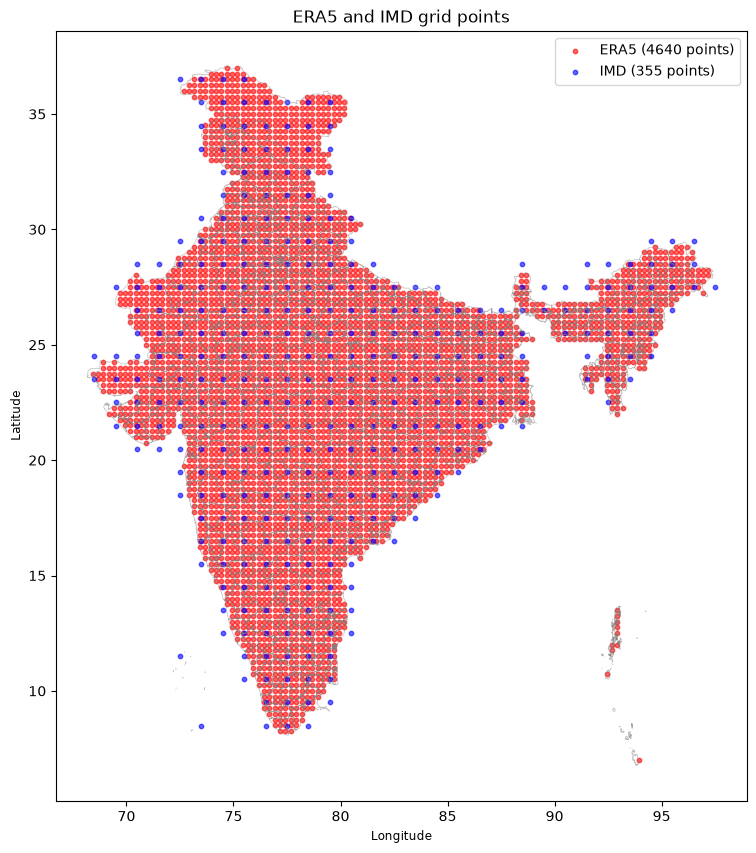

In [5]:
v.compare_grids(
    {"ERA5": era5, "IMD": imd}, polygons=districts, title="ERA5 and IMD grid points"
)

`check_grid_coverage` counts the grid points inside each district.

In [6]:
coverage = [
    v.check_grid_coverage(g, districts, polygon_id_col="district_code")
    for g in (imd, era5)
]
pd.DataFrame(coverage, index=["IMD", "ERA5"])[
    [
        "total_polygons",
        "covered_polygons",
        "empty_polygons",
        "coverage_percent",
        "median_points",
    ]
]

,total_polygons,covered_polygons,empty_polygons,coverage_percent,median_points
IMD,783,783,0,100.0,1.0
ERA5,783,783,0,100.0,5.0


## Aggregate IMD to districts with the two methods

In [7]:
pip = v.aggregate_to_polygons(
    imd,
    districts,
    "temperature",
    method="point_in_polygon",
    polygon_id_col="district_code",
)
nearest = v.aggregate_to_polygons(
    imd,
    districts,
    "temperature",
    method="nearest_centroid",
    polygon_id_col="district_code",
)
both = pip.rename(columns={"temperature": "pip"}).assign(nearest=nearest["temperature"])
both[["pip", "nearest"]].notna().sum()

/Users/mcclintock/github/varunayan/python/varunayan/spatial.py:94: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  key = nearest(polygons, polygons.geometry.centroid)


pip        250
nearest    783
dtype: int64

## Compare the maps

Gray districts have no value.

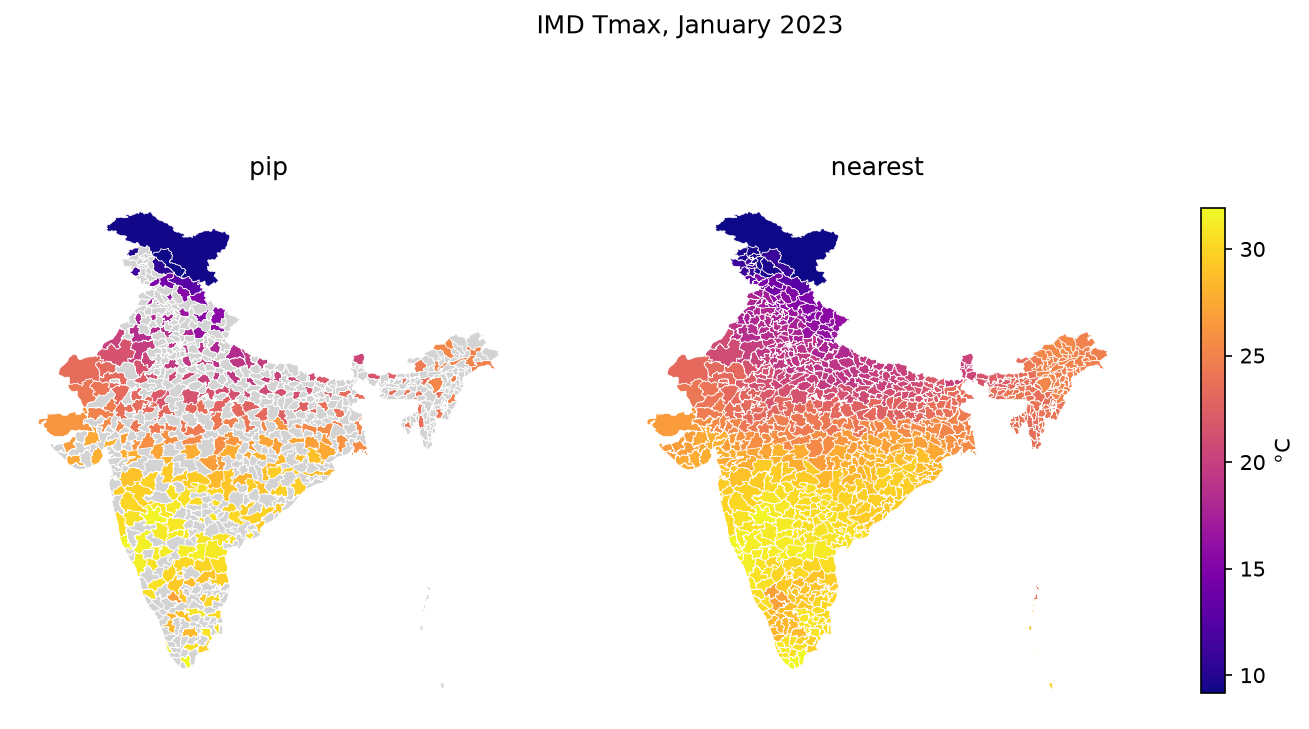

In [8]:
v.plot_map(
    both,
    ["pip", "nearest"],
    cmap="plasma",
    title="IMD Tmax, January 2023",
    legend_title="°C",
)

## Compare the values

For districts with a value from both methods, the scatter plot shows the agreement.

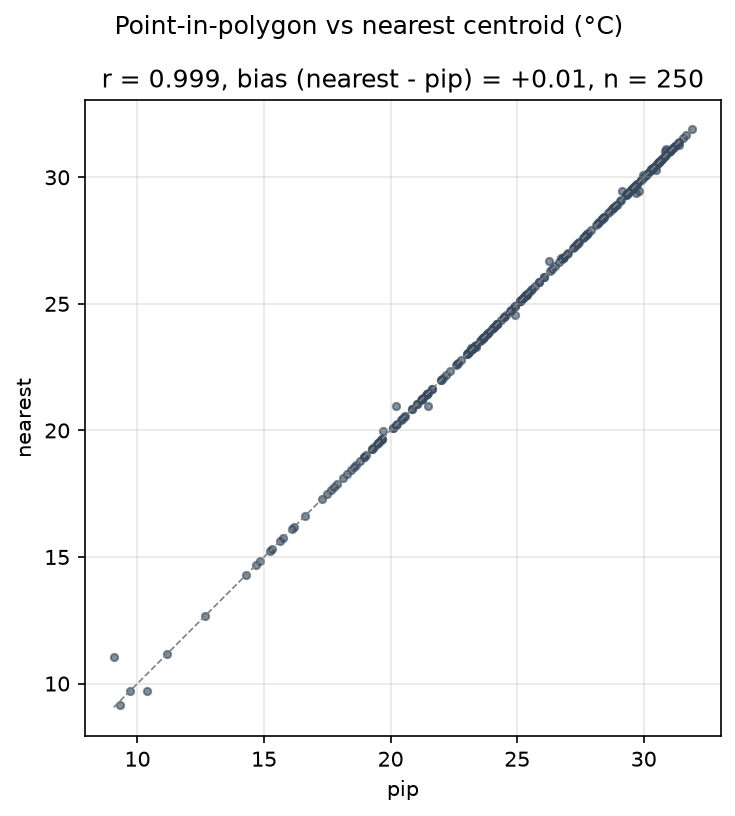

In [9]:
v.plot_scatter(
    both, "pip", "nearest", title="Point-in-polygon vs nearest centroid (°C)"
)

## Conclusion

The 1° IMD grid is much coarser than the 0.25° ERA5 grid. Only 250 of the 783 districts (32 %) contain an IMD grid point. ERA5 grid points are in 751 districts (96 %).

With the point-in-polygon method, 533 districts have no IMD value. The nearest-centroid method gives a value to all 783 districts. Where both methods give a value, they agree closely, because most of these districts contain only one IMD grid point. With `fill_empty=True`, the point-in-polygon method uses the nearest grid point for a district that has no grid point.